# Part 2 — Load balancing in a MoE model (EuroMoE-2.6B-A0.6B)
Run in a fresh session (do not reuse the Part 1 kernel: the model is reloaded for every run).

## Setup & config

In [1]:
!pip install -q torch==2.11.0 --index-url https://download.pytorch.org/whl/cu128
!pip install -q transformers==5.16.1

In [2]:
import os, gc, json, math, time, random, hashlib, inspect
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer, AutoConfig

MODEL_ID = "utter-project/EuroMoE-2.6B-A0.6B-2512"
WORK = "/kaggle/working"
RUN_DIR = f"{WORK}/part2_runs"
EVAL_CORPUS_PATH = "/kaggle/input/datasets/mykhailotkachenko/part1-eval/eval_corpus_kobza.jsonl"
DATA_PATH = f"{WORK}/part2_data.pt"
DEVICE = "cuda"
os.makedirs(RUN_DIR, exist_ok=True)

CFG2 = dict(
    model_id=MODEL_ID,
    transformers=transformers.__version__,
    torch=torch.__version__,
    # data
    seq_len=1024,
    split_mod=100, test_buckets=3, val_buckets=3,      # hash(doc_id) % 100 -> [0,3) test, [3,6) val, rest train
    min_doc_chars=500, min_cyrillic_ratio=0.7, max_doc_tokens=4096,
    n_val_chunks=40, n_test_chunks=120,
    # training (identical for every strategy)
    micro_bs=2, grad_accum=4, n_steps=300,
    lr_attn=2e-5, lr_router=1e-4,
    warmup_steps=20, min_lr_ratio=0.1, weight_decay=0.0, grad_clip=1.0,
    adam_betas=(0.9, 0.95),
    grad_checkpointing=True,
    eval_every=50, eval_bs=4,
    # balancing
    bias_update_rate=1e-3,
    z_coef=1e-3,
    seeds=[42, 43],
)
CFG2["tokens_per_step"] = CFG2["seq_len"] * CFG2["micro_bs"] * CFG2["grad_accum"]
CFG2["n_train_chunks"] = CFG2["n_steps"] * CFG2["micro_bs"] * CFG2["grad_accum"]
CFG2["train_token_budget"] = CFG2["n_train_chunks"] * CFG2["seq_len"]

with open(f"{WORK}/config_part2.json", "w") as f:
    json.dump(CFG2, f, indent=2)


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(CFG2["seeds"][0])
print(json.dumps(CFG2, indent=2))

{
  "model_id": "utter-project/EuroMoE-2.6B-A0.6B-2512",
  "transformers": "5.16.1",
  "torch": "2.11.0+cu128",
  "seq_len": 1024,
  "split_mod": 100,
  "test_buckets": 3,
  "val_buckets": 3,
  "min_doc_chars": 500,
  "min_cyrillic_ratio": 0.7,
  "max_doc_tokens": 4096,
  "n_val_chunks": 40,
  "n_test_chunks": 120,
  "micro_bs": 2,
  "grad_accum": 4,
  "n_steps": 300,
  "lr_attn": 2e-05,
  "lr_router": 0.0001,
  "warmup_steps": 20,
  "min_lr_ratio": 0.1,
  "weight_decay": 0.0,
  "grad_clip": 1.0,
  "adam_betas": [
    0.9,
    0.95
  ],
  "grad_checkpointing": true,
  "eval_every": 50,
  "eval_bs": 4,
  "bias_update_rate": 0.001,
  "z_coef": 0.001,
  "seeds": [
    42,
    43
  ],
  "tokens_per_step": 8192,
  "n_train_chunks": 2400,
  "train_token_budget": 2457600
}


## Model loading + model card

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)


def load_base_model():
    # Balancing losses are computed by our own code (see the router note below),
    # so the HF built-in aux loss is switched off explicitly.
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        dtype=torch.float16,
        device_map=DEVICE,
        output_router_logits=False,
        router_aux_loss_coef=0.0,
        router_jitter_noise=0.0,
    )
    model.config.use_cache = False
    return model


hub_cfg = AutoConfig.from_pretrained(MODEL_ID)   # untouched config, as published
model = load_base_model()
cfg = model.config
L, N, K = cfg.num_hidden_layers, cfg.num_local_experts, cfg.num_experts_per_tok

for key in ["num_hidden_layers", "hidden_size", "intermediate_size", "num_local_experts",
            "num_experts_per_tok", "router_aux_loss_coef", "router_jitter_noise",
            "output_router_logits", "sliding_window", "vocab_size", "tie_word_embeddings"]:
    print(f"{key:24s} {getattr(hub_cfg, key, None)}")

n_total = sum(p.numel() for p in model.parameters())
n_expert = sum(p.numel() for n_, p in model.named_parameters() if ".experts." in n_)
n_embed = model.model.embed_tokens.weight.numel()
if not cfg.tie_word_embeddings:
    n_embed += model.lm_head.weight.numel()
n_active = n_total - n_expert + n_expert * K / N
print(f"\ntotal params:  {n_total/1e9:.3f}B   (non-embedding {(n_total-n_embed)/1e9:.3f}B)")
print(f"expert params: {n_expert/1e9:.3f}B")
print(f"active params: {n_active/1e9:.3f}B   (non-embedding {(n_active-n_embed)/1e9:.3f}B)")
print(f"routed experts={N}, top-k={K}, shared experts=0 (Mixtral class)")

gate0 = model.model.layers[0].mlp.gate
print("\nrouter class:", type(gate0))
print(inspect.getsource(type(gate0).forward))

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/47.0k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 15.8MB            

tokenizer.json: downloading bytes:           |  0.00B            

tokenizer.model: reconstructing file:   0%|          |  0.00B / 2.41MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

num_hidden_layers        24
hidden_size              1024
intermediate_size        512
num_local_experts        64
num_experts_per_tok      8
router_aux_loss_coef     0.01
router_jitter_noise      0.0
output_router_logits     False
sliding_window           None
vocab_size               128000
tie_word_embeddings      True

total params:  2.612B   (non-embedding 2.480B)
expert params: 2.416B
active params: 0.498B   (non-embedding 0.367B)
routed experts=64, top-k=8, shared experts=0 (Mixtral class)

router class: <class 'transformers.models.mixtral.modeling_mixtral.MixtralTopKRouter'>
    def forward(self, hidden_states):
        hidden_states = hidden_states.reshape(-1, self.hidden_dim)
        router_logits = F.linear(hidden_states, self.weight)  # (seq_len, num_experts)
        router_probs = torch.nn.functional.softmax(router_logits.float(), dim=-1)
        router_top_value, router_indices = torch.topk(router_probs, self.top_k, dim=-1)  # (seq_len, top_k)
        router_top_value /= 

**Router note (transformers 5.0.0).** `MixtralTopKRouter.forward` overwrites `router_logits` with the softmax,
so what HF returns as "router_logits" (and what `output_router_logits=True` collects) are *probabilities*.
The built-in `load_balancing_loss_func` then applies softmax a second time. The check below shows it.
This is why logits, z-loss and the aux loss are computed from our own router module.

In [4]:
with torch.no_grad():
    h = torch.randn(8, cfg.hidden_size, device=DEVICE, dtype=torch.float16)
    rl, rs, ri = gate0(h)
is_probs = torch.allclose(rl.float().sum(-1), torch.ones(rl.shape[0], device=rl.device), atol=1e-3)
print(f"transformers {transformers.__version__}: HF 'router_logits' are "
      f"{'PROBABILITIES (5.0.0 bug)' if is_probs else 'real logits'}")

transformers 5.16.1: HF 'router_logits' are real logits


## Data: Kobza train / val / test (disjoint from Part 1 eval docs)

In [5]:
from datasets import load_dataset


def cyrillic_ratio(text: str) -> float:
    letters = [c for c in text[:5000] if c.isalpha()]
    if not letters:
        return 0.0
    return sum("\u0400" <= c <= "\u04ff" for c in letters) / len(letters)


def split_of(doc_id: str) -> str:
    b = int(hashlib.md5(doc_id.encode("utf-8")).hexdigest(), 16) % CFG2["split_mod"]
    if b < CFG2["test_buckets"]:
        return "test"
    if b < CFG2["test_buckets"] + CFG2["val_buckets"]:
        return "val"
    return "train"


def build_data():
    S = CFG2["seq_len"]
    with open(EVAL_CORPUS_PATH, encoding="utf-8") as f:
        part1_eval_ids = {json.loads(line)["id"] for line in f}

    need = {"train": CFG2["n_train_chunks"] * S, "val": CFG2["n_val_chunks"] * S, "test": CFG2["n_test_chunks"] * S}
    streams = {k: [] for k in need}
    doc_ids = {k: [] for k in need}
    stats = dict(seen=0, skipped_part1_eval=0, filtered=0)
    bos = [tokenizer.bos_token_id] if tokenizer.bos_token_id is not None else []
    eos = [tokenizer.eos_token_id]
    assert tokenizer.eos_token_id is not None

    ds = load_dataset("Goader/kobza", split="train", streaming=True)
    t0 = time.time()
    for ex in ds:
        stats["seen"] += 1
        if ex["id"] in part1_eval_ids:
            stats["skipped_part1_eval"] += 1
            continue
        text = ex["text"]
        if len(text) < CFG2["min_doc_chars"] or cyrillic_ratio(text) < CFG2["min_cyrillic_ratio"]:
            stats["filtered"] += 1
            continue
        sp = split_of(ex["id"])
        if len(streams[sp]) >= need[sp]:
            if all(len(streams[k]) >= need[k] for k in need):
                break
            continue
        ids = tokenizer(text[: CFG2["max_doc_tokens"] * 8], add_special_tokens=False)["input_ids"]
        streams[sp].extend(bos + ids[: CFG2["max_doc_tokens"]] + eos)
        doc_ids[sp].append(ex["id"])
        if stats["seen"] % 5000 == 0:
            print({k: f"{len(v)/need[k]:.0%}" for k, v in streams.items()}, f"{time.time()-t0:.0f}s")

    for k in need:
        assert len(streams[k]) >= need[k], f"not enough data for {k}"
    assert not (set(doc_ids["train"]) & part1_eval_ids)
    assert not (set(doc_ids["train"]) & (set(doc_ids["val"]) | set(doc_ids["test"])))

    data = {}
    for k in need:
        n = need[k] // S
        data[k] = torch.tensor(streams[k][: n * S], dtype=torch.int32).view(n, S)
    for k in ["val", "test"]:   # bytes of the predicted tokens, for bits-per-byte
        data[f"{k}_bytes"] = torch.tensor(
            [len(tokenizer.decode(c[1:].tolist()).encode("utf-8")) for c in data[k]], dtype=torch.int64)
    data["meta"] = dict(stats=stats, n_docs={k: len(v) for k, v in doc_ids.items()},
                        doc_ids={k: v for k, v in doc_ids.items() if k != "train"})
    return data


if os.path.exists(DATA_PATH):
    DATA = torch.load(DATA_PATH)
else:
    DATA = build_data()
    torch.save(DATA, DATA_PATH)

print(DATA["meta"]["stats"], DATA["meta"]["n_docs"])
for k in ["train", "val", "test"]:
    print(f"{k:5s} chunks={DATA[k].shape[0]:5d}  tokens={DATA[k].numel():,}")

README.md:   0%|          | 0.00/7.61k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/95 [00:00<?, ?it/s]

{'seen': 6280, 'skipped_part1_eval': 10, 'filtered': 641} {'train': 2929, 'val': 39, 'test': 151}
train chunks= 2400  tokens=2,457,600
val   chunks=   40  tokens=40,960
test  chunks=  120  tokens=122,880


## Router instrumentation: own router module + recorder

In [6]:
class RouterRecorder:
    """Collects (logits, probs, top-k idx) of every layer for exactly one forward pass.

    Recording is switched off before backward, so recomputation under gradient
    checkpointing does not append duplicates."""

    def __init__(self, n_layers: int):
        self.n_layers = n_layers
        self.recording = False
        self.records = [None] * n_layers

    def start(self):
        self.records = [None] * self.n_layers
        self.recording = True

    def stop(self):
        self.recording = False
        assert all(r is not None for r in self.records), "a router did not record"
        recs, self.records = self.records, [None] * self.n_layers
        return recs

    def record(self, layer_idx, logits, probs, idx):
        if not self.recording:
            return
        assert self.records[layer_idx] is None, f"layer {layer_idx} recorded twice in one forward"
        self.records[layer_idx] = (logits, probs, idx)


class BalancedRouter(nn.Module):
    """Drop-in replacement for MixtralTopKRouter (same return signature).

    - logits in fp32 (needed for z-loss and logsumexp)
    - optional per-expert bias (aux-loss-free balancing): used ONLY for top-k selection,
      gate values are always the unbiased softmax probs of the selected experts, renormalized."""

    def __init__(self, orig_gate, layer_idx: int, recorder: RouterRecorder):
        super().__init__()
        self.layer_idx = layer_idx
        self.recorder = recorder
        self.top_k = orig_gate.top_k
        self.num_experts = orig_gate.num_experts
        self.hidden_dim = orig_gate.hidden_dim
        self.weight = nn.Parameter(orig_gate.weight.detach().float().clone())
        self.register_buffer("expert_bias", torch.zeros(self.num_experts, dtype=torch.float32,
                                                        device=self.weight.device), persistent=False)
        self.use_bias = False

    def forward(self, hidden_states):
        x = hidden_states.reshape(-1, self.hidden_dim)
        with torch.autocast(device_type=x.device.type, enabled=False):
            logits = F.linear(x.float(), self.weight)
            probs = logits.softmax(dim=-1)
            scores = probs + self.expert_bias if self.use_bias else probs
            idx = scores.topk(self.top_k, dim=-1).indices
            gates = probs.gather(-1, idx)
            gates = gates / gates.sum(dim=-1, keepdim=True)
        self.recorder.record(self.layer_idx, logits, probs, idx)
        return logits, gates, idx


def patch_routers(model, recorder):
    routers = []
    for i, layer in enumerate(model.model.layers):
        new_gate = BalancedRouter(layer.mlp.gate, i, recorder)
        layer.mlp.gate = new_gate
        routers.append(new_gate)
    return routers

### Equivalence test: our router vs the original HF router (on real hidden states)

In [7]:
captured = {}
hooks = [
    layer.mlp.gate.register_forward_hook(
        lambda m, inp, out, i=i: captured.__setitem__(i, (inp[0].detach(), out[1].detach(), out[2].detach())))
    for i, layer in enumerate(model.model.layers)
]
sample = DATA["val"][:1, :512].to(DEVICE).long()
with torch.no_grad():
    loss_orig = model(input_ids=sample, labels=sample).loss.item()
for hk in hooks:
    hk.remove()

recorder = RouterRecorder(L)
routers = patch_routers(model, recorder)

agree, wdiff = [], []
with torch.no_grad():
    for i, r in enumerate(routers):
        x, w_o, idx_o = captured[i]
        _, w_n, idx_n = r(x)
        same = (idx_o.sort(-1).values == idx_n.sort(-1).values).all(-1)
        agree.append(same.float().mean().item())
        w_o_sorted = w_o.float().gather(-1, idx_o.argsort(-1))[same]
        w_n_sorted = w_n.gather(-1, idx_n.argsort(-1))[same]
        wdiff.append((w_o_sorted - w_n_sorted).abs().max().item() if same.any() else float("nan"))
    loss_new = model(input_ids=sample, labels=sample).loss.item()

print(f"top-k set agreement: min={min(agree):.4f} mean={np.mean(agree):.4f}")
print(f"gate weight max abs diff (agreeing tokens): {np.nanmax(wdiff):.2e}")
print(f"LM loss orig={loss_orig:.4f}  patched={loss_new:.4f}  diff={abs(loss_orig-loss_new):.2e}")
# fp16 vs fp32 logits can flip near-ties, so agreement is ~0.99, not exactly 1
assert min(agree) > 0.97 and np.nanmax(wdiff) < 1e-2 and abs(loss_orig - loss_new) < 2e-2

top-k set agreement: min=0.9844 mean=0.9943
gate weight max abs diff (agreeing tokens): 3.20e-04
LM loss orig=1.8537  patched=1.8548  diff=1.17e-03


### Bias test: bias changes selection only, never the gate values

In [8]:
r0 = routers[0]
x0 = captured[0][0]
r0.use_bias = True
r0.expert_bias.zero_()
r0.expert_bias[0] = 10.0
with torch.no_grad():
    logits0, gates0, idx0 = r0(x0)
assert (idx0 == 0).any(-1).all(), "bias did not force expert 0 into top-k"
expected = logits0.softmax(-1).gather(-1, idx0)
expected = expected / expected.sum(-1, keepdim=True)
assert torch.allclose(gates0, expected), "bias leaked into gate values"
r0.expert_bias.zero_()
r0.use_bias = False
print("bias test OK")

bias test OK


## Metrics

In [9]:
def load_fractions(counts):
    """counts: (L, N) routed slots per expert -> f_i (rows sum to 1)."""
    counts = counts.double()
    return counts / counts.sum(-1, keepdim=True)


def maxvio(counts):
    """Per layer: (max_i load_i - mean load) / mean load."""
    counts = counts.double()
    mean = counts.mean(-1)
    return (counts.max(-1).values - mean) / mean


def load_entropy(counts):
    """Normalized entropy of the load distribution, 1 = perfectly uniform."""
    f = load_fractions(counts)
    ent = -(f * f.clamp_min(1e-12).log()).sum(-1)
    return ent / math.log(counts.shape[-1])


def random_router_floor(n_tokens, n_experts=None, top_k=None, n_rep=20, seed=0):
    """MaxVio / entropy of a uniformly random top-k router on the same number of tokens."""
    n_experts, top_k = n_experts or N, top_k or K
    g = torch.Generator().manual_seed(seed)
    mv, ent = [], []
    for _ in range(n_rep):
        idx = torch.rand(n_tokens, n_experts, generator=g).topk(top_k, dim=-1).indices
        c = torch.bincount(idx.flatten(), minlength=n_experts)[None]
        mv.append(maxvio(c).item())
        ent.append(load_entropy(c).item())
    return dict(maxvio_mean=float(np.mean(mv)), maxvio_std=float(np.std(mv)),
                entropy_mean=float(np.mean(ent)), entropy_std=float(np.std(ent)))


def jaccard_per_layer(idx_a, idx_b, n_experts=None):
    """idx_*: (L, T, K) top-k sets of the same tokens. Mean Jaccard overlap per layer."""
    n_experts = n_experts or N
    out = []
    for l in range(idx_a.shape[0]):
        a = torch.zeros(idx_a.shape[1], n_experts, dtype=torch.bool).scatter_(1, idx_a[l].long(), True)
        b = torch.zeros(idx_b.shape[1], n_experts, dtype=torch.bool).scatter_(1, idx_b[l].long(), True)
        out.append(((a & b).sum(1).float() / (a | b).sum(1).float()).mean().item())
    return out


@torch.no_grad()
def evaluate(model, recorder, chunks, chunk_bytes=None, keep_idx=False, bs=None):
    """Teacher-forced LM loss + per-layer routing statistics on fixed held-out chunks."""
    bs = bs or CFG2["eval_bs"]
    was_training = model.training
    model.eval()
    counts = torch.zeros(L, N, dtype=torch.float64)
    lse_sum = torch.zeros(L, dtype=torch.float64)
    nll_sum, n_pred, n_routed = 0.0, 0, 0
    idx_store = []
    for i in range(0, chunks.shape[0], bs):
        batch = chunks[i:i + bs].to(DEVICE).long()
        recorder.start()
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(input_ids=batch, labels=batch, use_cache=False)
        recs = recorder.stop()
        n = batch.shape[0] * (batch.shape[1] - 1)
        nll_sum += out.loss.float().item() * n
        n_pred += n
        n_routed += recs[0][2].shape[0]
        layer_idx = []
        for l, (logits, probs, idx) in enumerate(recs):
            counts[l] += torch.bincount(idx.flatten(), minlength=N).double().cpu()
            lse_sum[l] += torch.logsumexp(logits, dim=-1).double().sum().cpu()
            if keep_idx:
                layer_idx.append(idx.to(torch.uint8).cpu())
        if keep_idx:
            idx_store.append(torch.stack(layer_idx))   # (L, T_batch, K)
        del out, recs
    if was_training:
        model.train()
    loss = nll_sum / n_pred
    res = dict(loss=loss, ppl=math.exp(loss), n_tokens=n_routed, counts=counts,
               maxvio=maxvio(counts), entropy=load_entropy(counts), lse=lse_sum / n_routed)
    if chunk_bytes is not None:
        res["bpb"] = nll_sum / math.log(2) / chunk_bytes[: chunks.shape[0]].sum().item()
    if keep_idx:
        res["idx"] = torch.cat(idx_store, dim=1)   # (L, T, K)
    return res

## Base model analysis

Base model on test: ppl=6.947  bpb=0.4978  tokens=122,880  (24s)
MaxVio scale: random router = 0.018 ± 0.003 (noise floor),  ceiling = N/K-1 = 7


,block,MaxVio,% of ceiling,entropy,top expert,top expert: % tokens,overloaded >2x,rare <0.25x,dead <0.01x,router lse
layer,,,,,,,,,,
0,early,6.60,94%,0.762,58,95.0%,8,29,6,0.007
1,early,5.29,76%,0.869,56,78.6%,8,19,0,0.028
2,early,4.88,70%,0.937,17,73.5%,5,4,0,0.014
3,early,5.60,80%,0.897,33,82.5%,4,6,0,0.027
4,early,6.46,92%,0.932,57,93.2%,3,3,0,0.025
5,early,6.47,92%,0.937,24,93.4%,2,3,0,0.007
6,early,1.28,18%,0.977,57,28.5%,2,1,0,0.013
7,early,1.75,25%,0.973,26,34.3%,2,2,0,0.015
8,middle,6.31,90%,0.940,11,91.3%,2,4,0,0.012


,MaxVio,entropy,top expert: % tokens,overloaded >2x,rare <0.25x,dead <0.01x
block,,,,,,
early,4.79,0.91,72.37,4.25,8.38,0.75
middle,5.66,0.93,83.30,4.12,6.12,0.00
late,6.63,0.81,95.39,7.12,22.12,5.75


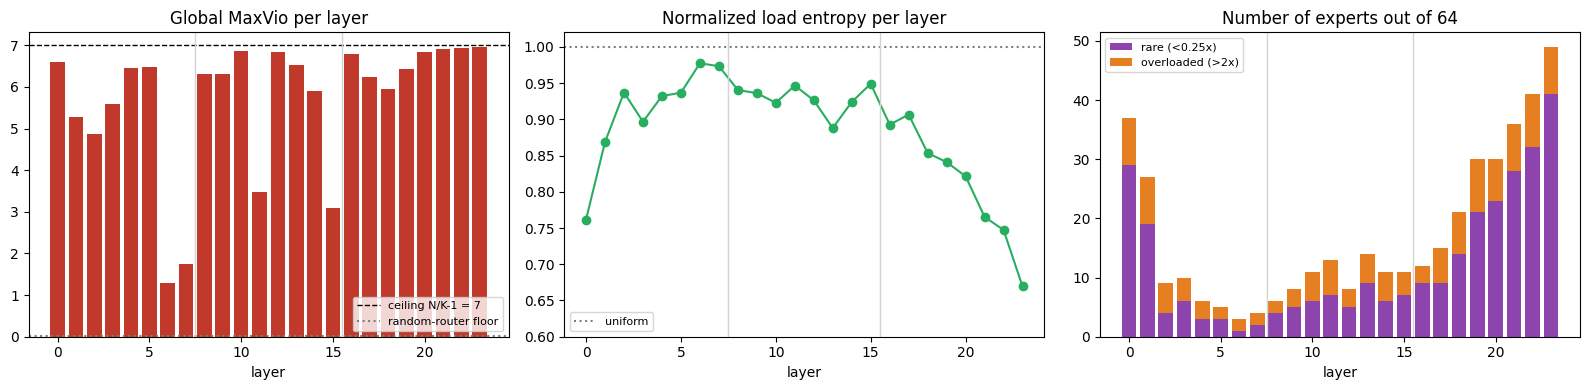

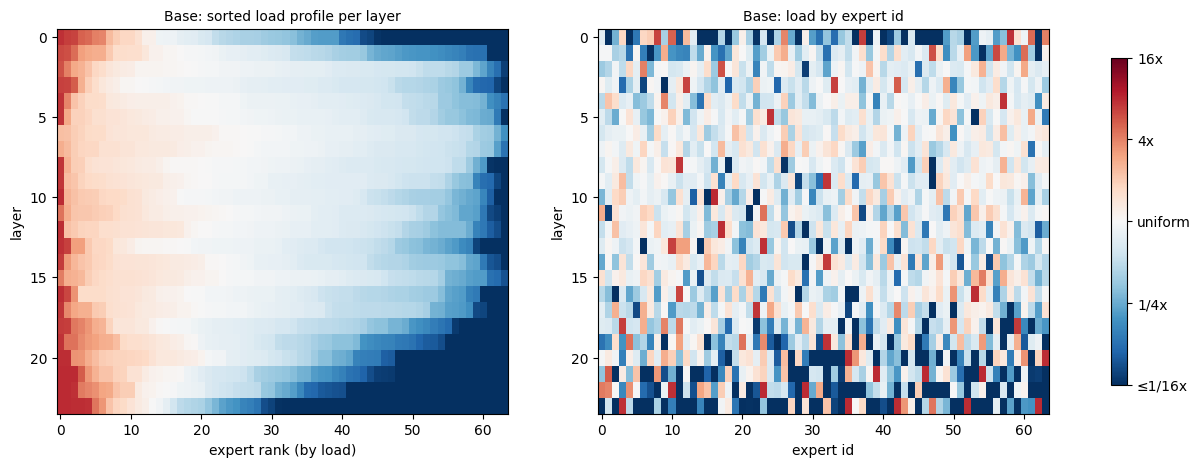

Experts present in the top-8 of >90% of tokens: 24 (layers with one: 15/24)
  L0:e58 (95%), L4:e57 (93%), L5:e24 (93%), L8:e11 (91%), L9:e32 (91%), L10:e16 (98%), L12:e17 (98%), L13:e23 (94%), L16:e53 (97%), L17:e22 (91%), L19:e32 (93%), L20:e35 (98%), L20:e63 (97%), L21:e39 (99%), L21:e46 (99%), L21:e54 (99%), L22:e10 (95%), L22:e23 (99%), L22:e29 (98%), L23:e3 (94%), L23:e35 (100%), L23:e42 (96%), L23:e52 (98%), L23:e62 (99%)


In [10]:
# ===== Base model analysis (replaces the old cell) =====
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# ---------- 1. eval + artifacts needed later by train_run / results ----------
t0 = time.time()
base = evaluate(model, recorder, DATA["test"], DATA["test_bytes"], keep_idx=True)
torch.save(base["idx"], f"{RUN_DIR}/base_test_idx.pt")
torch.save(base["counts"], f"{RUN_DIR}/base_test_counts.pt")
with open(f"{RUN_DIR}/base_summary.json", "w") as f:
    json.dump(dict(ppl=base["ppl"], bpb=base["bpb"], n_tokens=base["n_tokens"],
                   maxvio_per_layer=base["maxvio"].tolist(), entropy_per_layer=base["entropy"].tolist(),
                   lse_per_layer=base["lse"].tolist()), f, indent=2)

floor_global = random_router_floor(base["n_tokens"])
floor_batch = random_router_floor(CFG2["tokens_per_step"])
with open(f"{RUN_DIR}/noise_floor.json", "w") as f:
    json.dump(dict(global_=floor_global, batch=floor_batch, n_tokens_global=base["n_tokens"],
                   n_tokens_batch=CFG2["tokens_per_step"]), f, indent=2)

MAXVIO_CEIL = N / K - 1          # one expert in the top-k of EVERY token
print(f"Base model on test: ppl={base['ppl']:.3f}  bpb={base['bpb']:.4f}  "
      f"tokens={base['n_tokens']:,}  ({time.time()-t0:.0f}s)")
print(f"MaxVio scale: random router = {floor_global['maxvio_mean']:.3f} ± {floor_global['maxvio_std']:.3f} "
      f"(noise floor),  ceiling = N/K-1 = {MAXVIO_CEIL:.0f}")

# ---------- 2. per-layer table ----------
rel = (load_fractions(base["counts"]) * N).float()   # load / uniform share, 1.0 = uniform
cover = rel * K / N                                  # share of TOKENS whose top-k contains the expert
blocks = np.array_split(np.arange(L), 3)
block_of = {l: name for name, ls in zip(["early", "middle", "late"], blocks) for l in ls}

df = pd.DataFrame({
    "block": [block_of[l] for l in range(L)],
    "MaxVio": base["maxvio"].numpy(),
    "% of ceiling": base["maxvio"].numpy() / MAXVIO_CEIL * 100,
    "entropy": base["entropy"].numpy(),
    "top expert": rel.argmax(1).numpy(),
    "top expert: % tokens": cover.max(1).values.numpy() * 100,
    "overloaded >2x": (rel > 2).sum(1).numpy(),
    "rare <0.25x": (rel < 0.25).sum(1).numpy(),
    "dead <0.01x": (rel < 0.01).sum(1).numpy(),
    "router lse": base["lse"].numpy(),
}, index=pd.RangeIndex(L, name="layer"))

display(df.style
          .format({"MaxVio": "{:.2f}", "% of ceiling": "{:.0f}%", "entropy": "{:.3f}",
                   "top expert: % tokens": "{:.1f}%", "router lse": "{:.3f}"})
          .background_gradient(subset=["MaxVio"], cmap="Reds", vmin=0, vmax=MAXVIO_CEIL)
          .background_gradient(subset=["entropy"], cmap="Greens", vmin=0.6, vmax=1.0)
          .background_gradient(subset=["rare <0.25x"], cmap="Purples", vmin=0, vmax=N // 2))

summary = df.groupby("block", sort=False)[
    ["MaxVio", "entropy", "top expert: % tokens", "overloaded >2x", "rare <0.25x", "dead <0.01x"]].mean()
display(summary.style.format("{:.2f}"))
df.to_csv(f"{WORK}/part2_base_per_layer.csv")

# ---------- 3. per-layer curves ----------
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
layers = np.arange(L)

axes[0].bar(layers, df["MaxVio"], color="#c0392b")
axes[0].axhline(MAXVIO_CEIL, color="k", ls="--", lw=1, label=f"ceiling N/K-1 = {MAXVIO_CEIL:.0f}")
axes[0].axhline(floor_global["maxvio_mean"], color="grey", ls=":", lw=1.5, label="random-router floor")
axes[0].set_title("Global MaxVio per layer")
axes[0].legend(fontsize=8, loc="lower right")

axes[1].plot(layers, df["entropy"], marker="o", color="#27ae60")
axes[1].axhline(1.0, color="grey", ls=":", lw=1.5, label="uniform")
axes[1].set_title("Normalized load entropy per layer")
axes[1].set_ylim(0.6, 1.02)
axes[1].legend(fontsize=8)

axes[2].bar(layers, df["rare <0.25x"], color="#8e44ad", label="rare (<0.25x)")
axes[2].bar(layers, df["overloaded >2x"], bottom=df["rare <0.25x"], color="#e67e22", label="overloaded (>2x)")
axes[2].set_title(f"Number of experts out of {N}")
axes[2].legend(fontsize=8)

for ax in axes:
    ax.set_xlabel("layer")
    for b in blocks[1:]:
        ax.axvline(b[0] - 0.5, color="lightgrey", lw=1)
plt.tight_layout()
plt.savefig(f"{WORK}/part2_base_layer_curves.png", dpi=150)
plt.show()

# ---------- 4. heatmaps: diverging log2 scale, white = uniform ----------
def plot_load_heatmap(counts, title, ax, sort=False):
    """log2(load / uniform): red = overloaded, blue = underused, white = uniform.
    sort=True sorts experts by load inside each layer (shape of the distribution);
    sort=False keeps expert ids (needed to compare strategies expert-by-expert)."""
    r = (load_fractions(counts) * N).float().clamp_min(1 / 16)
    if sort:
        r = r.sort(dim=1, descending=True).values
    im = ax.imshow(torch.log2(r).numpy(), aspect="auto", cmap="RdBu_r", vmin=-4, vmax=4,
                   interpolation="nearest")
    ax.set_xlabel("expert rank (by load)" if sort else "expert id")
    ax.set_ylabel("layer")
    ax.set_title(title, fontsize=10)
    return im


fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_load_heatmap(base["counts"], "Base: sorted load profile per layer", axes[0], sort=True)
im = plot_load_heatmap(base["counts"], "Base: load by expert id", axes[1], sort=False)
cbar = fig.colorbar(im, ax=axes, shrink=0.85, ticks=[-4, -2, 0, 2, 4])
cbar.ax.set_yticklabels(["≤1/16x", "1/4x", "uniform", "4x", "16x"])
plt.savefig(f"{WORK}/part2_heatmap_base.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- 5. near "always-on" experts (implicit shared experts) ----------
always_on = [(l, int(e), cover[l, e].item() * 100)
             for l in range(L) for e in (cover[l] > 0.9).nonzero().flatten()]
print(f"Experts present in the top-{K} of >90% of tokens: {len(always_on)} (layers with one: "
      f"{len({l for l, _, _ in always_on})}/{L})")
print("  " + ", ".join(f"L{l}:e{e} ({c:.0f}%)" for l, e, c in always_on))

## Balancing losses + sanity checks (before any training)

In [11]:
def balance_losses(recs):
    """Switch/GShard aux loss N * sum_i f_i P_i (== 1 at perfect balance, NOT k as in HF)
    and router z-loss mean(logsumexp(logits)^2). Both averaged over layers."""
    aux_terms, z_terms, counts = [], [], []
    for logits, probs, idx in recs:
        T = idx.shape[0]
        c = torch.bincount(idx.flatten(), minlength=N).float()
        f = c / (T * K)                 # not differentiable
        P = probs.mean(0)               # differentiable surrogate
        aux_terms.append(N * (f * P).sum())
        z_terms.append(torch.logsumexp(logits, dim=-1).pow(2).mean())
        counts.append(c)
    return torch.stack(aux_terms).mean(), torch.stack(z_terms).mean(), torch.stack(counts).detach()


for p in model.parameters():
    p.requires_grad_(False)
for r in routers:
    r.weight.requires_grad_(True)
    r.weight.grad = None

batch = DATA["train"][: CFG2["micro_bs"]].to(DEVICE).long()
recorder.start()
with torch.autocast("cuda", dtype=torch.float16):
    out = model(input_ids=batch, labels=batch, use_cache=False)
recs = recorder.stop()
aux, z, _ = balance_losses(recs)

assert getattr(out, "aux_loss", None) is None, "HF aux loss is active, it would be added twice"
assert aux.item() > 0 and z.item() > 0
tot_a = (out.loss + 1e-3 * aux).item()
tot_b = (out.loss + 1e-2 * aux).item()
assert tot_a != tot_b, "aux coefficient has no effect"
aux.backward()
g = torch.stack([r.weight.grad.norm() for r in routers])
assert (g > 0).all(), "aux loss gradient does not reach every router"
print(f"LM={out.loss.item():.4f} aux={aux.item():.4f} (1.0 = perfect balance) z={z.item():.3f}")
print(f"total @1e-3={tot_a:.5f}  @1e-2={tot_b:.5f}")
print(f"router grad norm from aux: min={g.min().item():.2e} max={g.max().item():.2e}")
for r in routers:
    r.weight.grad = None
del out, recs, aux, z, model, routers, recorder
gc.collect()
torch.cuda.empty_cache()

LM=1.8071 aux=1.9740 (1.0 = perfect balance) z=0.010
total @1e-3=1.80912  @1e-2=1.82688
router grad norm from aux: min=4.51e-02 max=1.89e+00


## Pre-registered predictions (fill in BEFORE running the strategies)

In [12]:
PREDICTIONS = {
    "no_balance":    dict(ppl_delta_pct=0.0, maxvio=5.7, jaccard=0.90),
    "aux_1e-3":      dict(ppl_delta_pct=0.0, maxvio=5.7, jaccard=0.90),
    "aux_1e-2":      dict(ppl_delta_pct=0.3, maxvio=5.3, jaccard=0.87),
    "aux_1e-1":      dict(ppl_delta_pct=1.5, maxvio=4.0, jaccard=0.75),
    "loss_free":     dict(ppl_delta_pct=3.0, maxvio=1.0, jaccard=0.50),
    "aux_1e-3+z":    dict(ppl_delta_pct=0.0, maxvio=5.7, jaccard=0.90),
    "frozen_router": dict(ppl_delta_pct=0.1, maxvio=5.7, jaccard=0.93),
}
pred_path = f"{RUN_DIR}/predictions.json"
if not os.path.exists(pred_path):
    with open(pred_path, "w") as f:
        json.dump(dict(timestamp=time.strftime("%Y-%m-%d %H:%M:%S"), predictions=PREDICTIONS), f, indent=2)

## Continued pretraining
Trainable: attention projections (fp32 master copy) + routers. Experts, embeddings, norms, lm_head are frozen
(full fine-tuning of 2.6B params with AdamW does not fit a T4). Same data order / budget / hparams per seed.

In [13]:
STRATEGIES = {
    "no_balance":    dict(aux=0.0,  z=0.0,             loss_free=False, router_lr=CFG2["lr_router"]),
    "aux_1e-3":      dict(aux=1e-3, z=0.0,             loss_free=False, router_lr=CFG2["lr_router"]),
    "aux_1e-2":      dict(aux=1e-2, z=0.0,             loss_free=False, router_lr=CFG2["lr_router"]),
    "aux_1e-1":      dict(aux=1e-1, z=0.0,             loss_free=False, router_lr=CFG2["lr_router"]),
    "loss_free":     dict(aux=0.0,  z=0.0,             loss_free=True,  router_lr=CFG2["lr_router"]),
    "aux_1e-3+z":    dict(aux=1e-3, z=CFG2["z_coef"],  loss_free=False, router_lr=CFG2["lr_router"]),
    "frozen_router": dict(aux=0.0,  z=0.0,             loss_free=False, router_lr=0.0),
}
with open(f"{RUN_DIR}/strategies.json", "w") as f:
    json.dump(STRATEGIES, f, indent=2)


def setup_trainable(model, routers, train_router: bool):
    for p in model.parameters():
        p.requires_grad_(False)
    attn_params = []
    for layer in model.model.layers:
        for p in layer.self_attn.parameters():
            p.data = p.data.float()       # fp32 master weights; autocast runs the matmuls in fp16
            p.requires_grad_(True)
            attn_params.append(p)
    for r in routers:
        r.weight.requires_grad_(train_router)
    return attn_params


def make_lr_lambda(n_steps):
    w, m = CFG2["warmup_steps"], CFG2["min_lr_ratio"]

    def f(step):
        if step < w:
            return (step + 1) / w
        prog = (step - w) / max(1, n_steps - w)
        return m + (1 - m) * 0.5 * (1 + math.cos(math.pi * prog))
    return f


@torch.no_grad()
def update_expert_bias(routers, step_counts, rate):
    """Aux-loss-free balancing (Wang et al., 2024): b_i += u * sign(mean_load - load_i)."""
    for l, r in enumerate(routers):
        c = step_counts[l].to(r.expert_bias.device).float()
        r.expert_bias += rate * torch.sign(c.mean() - c)


def summarize_eval(res, base_idx=None):
    out = dict(loss=res["loss"], ppl=res["ppl"],
               maxvio_per_layer=res["maxvio"].tolist(), maxvio_mean=res["maxvio"].mean().item(),
               maxvio_max=res["maxvio"].max().item(),
               entropy_per_layer=res["entropy"].tolist(), entropy_mean=res["entropy"].mean().item(),
               lse_mean=res["lse"].mean().item())
    if "bpb" in res:
        out["bpb"] = res["bpb"]
    if base_idx is not None and "idx" in res:
        jac = jaccard_per_layer(base_idx, res["idx"])
        out.update(jaccard_per_layer=jac, jaccard_mean=float(np.mean(jac)))
    return out


def train_run(name, strat, seed, n_steps=None, save=True):
    n_steps = n_steps or CFG2["n_steps"]
    out_path = f"{RUN_DIR}/{name}__seed{seed}.json"
    if save and os.path.exists(out_path):
        print(f"[{name} s{seed}] already done, loading")
        with open(out_path) as f:
            return json.load(f)

    set_seed(seed)
    torch.cuda.reset_peak_memory_stats()
    model = load_base_model()
    recorder = RouterRecorder(L)
    routers = patch_routers(model, recorder)
    for r in routers:
        r.use_bias = strat["loss_free"]
    attn_params = setup_trainable(model, routers, train_router=strat["router_lr"] > 0)

    groups = [dict(params=attn_params, lr=CFG2["lr_attn"])]
    if strat["router_lr"] > 0:
        groups.append(dict(params=[r.weight for r in routers], lr=strat["router_lr"]))
    trainable = [p for g_ in groups for p in g_["params"]]
    opt = torch.optim.AdamW(groups, betas=CFG2["adam_betas"], weight_decay=CFG2["weight_decay"])
    sched = torch.optim.lr_scheduler.LambdaLR(opt, make_lr_lambda(n_steps))
    scaler = torch.amp.GradScaler("cuda")
    if CFG2["grad_checkpointing"]:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.train()

    base_idx = torch.load(f"{RUN_DIR}/base_test_idx.pt")
    train_chunks = DATA["train"]
    order = torch.randperm(train_chunks.shape[0], generator=torch.Generator().manual_seed(seed))
    mb, ga = CFG2["micro_bs"], CFG2["grad_accum"]

    hist = dict(step=[], lm_loss=[], aux=[], z=[], batch_maxvio_mean=[], batch_maxvio_max=[],
                batch_entropy_mean=[], bias_absmax=[], val=[])
    t0, ptr = time.time(), 0
    for step in range(n_steps):
        step_counts = torch.zeros(L, N, device=DEVICE)
        lm_acc = aux_acc = z_acc = 0.0
        for _ in range(ga):
            batch = train_chunks[order[ptr:ptr + mb]].to(DEVICE).long()
            ptr += mb
            recorder.start()
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(input_ids=batch, labels=batch, use_cache=False)
            recs = recorder.stop()            # stop BEFORE backward (checkpoint recompute must not record)
            aux, z, counts = balance_losses(recs)
            loss = out.loss.float() + strat["aux"] * aux + strat["z"] * z
            scaler.scale(loss / ga).backward()
            step_counts += counts
            lm_acc += out.loss.item() / ga
            aux_acc += aux.item() / ga
            z_acc += z.item() / ga
            del out, recs, loss, aux, z

        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(trainable, CFG2["grad_clip"])
        scaler.step(opt)
        scaler.update()
        sched.step()
        opt.zero_grad(set_to_none=True)
        if strat["loss_free"]:
            update_expert_bias(routers, step_counts, CFG2["bias_update_rate"])

        mv = maxvio(step_counts.cpu())
        hist["step"].append(step)
        hist["lm_loss"].append(lm_acc)
        hist["aux"].append(aux_acc)
        hist["z"].append(z_acc)
        hist["batch_maxvio_mean"].append(mv.mean().item())
        hist["batch_maxvio_max"].append(mv.max().item())
        hist["batch_entropy_mean"].append(load_entropy(step_counts.cpu()).mean().item())
        hist["bias_absmax"].append(max(r.expert_bias.abs().max().item() for r in routers))

        if (step + 1) % CFG2["eval_every"] == 0 or step == n_steps - 1:
            v = evaluate(model, recorder, DATA["val"][: CFG2["n_val_chunks"]], DATA["val_bytes"])
            hist["val"].append(dict(step=step, **{k: x for k, x in summarize_eval(v).items()
                                                 if not k.endswith("per_layer")}))
            print(f"[{name} s{seed}] step {step+1}/{n_steps} lm={lm_acc:.4f} aux={aux_acc:.4f} "
                  f"batchMaxVio={mv.mean():.3f} val_ppl={v['ppl']:.3f} val_MaxVio={v['maxvio'].mean():.3f} "
                  f"({time.time()-t0:.0f}s)")
    train_time = time.time() - t0

    test_chunks = DATA["test"] if save else DATA["test"][:8]      # smoke run: tiny test eval, no drift
    test = evaluate(model, recorder, test_chunks, DATA["test_bytes"], keep_idx=save)
    result = dict(name=name, seed=seed, strategy=strat, n_steps=n_steps,
                  tokens_seen=n_steps * CFG2["tokens_per_step"], train_time_s=train_time,
                  peak_mem_gb=torch.cuda.max_memory_allocated() / 1e9,
                  test=summarize_eval(test, base_idx if save else None),
                  test_counts=test["counts"].tolist(), history=hist)
    if save:
        with open(out_path, "w") as f:
            json.dump(result, f)
        torch.save({f"layer{l}": dict(weight=r.weight.detach().cpu(), bias=r.expert_bias.cpu())
                    for l, r in enumerate(routers)}, f"{RUN_DIR}/{name}__seed{seed}__routers.pt")
    print(f"[{name} s{seed}] DONE train {train_time/60:.1f} min, test ppl={result['test']['ppl']:.3f}, "
          f"MaxVio={result['test']['maxvio_mean']:.3f}, jaccard={result['test'].get('jaccard_mean', float('nan')):.3f}, "
          f"peak mem {result['peak_mem_gb']:.1f} GB")

    del model, routers, recorder, opt, sched, scaler, trainable, attn_params
    gc.collect()
    torch.cuda.empty_cache()
    return result

### All strategies, seed 1 (resumable: finished runs are loaded from disk)

In [14]:
RESULTS = {}
for name, strat in STRATEGIES.items():
    RESULTS[(name, CFG2["seeds"][0])] = train_run(name, strat, CFG2["seeds"][0])

Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

[no_balance s42] step 50/300 lm=2.0530 aux=1.9915 batchMaxVio=5.725 val_ppl=7.099 val_MaxVio=5.711 (305s)
[no_balance s42] step 100/300 lm=2.0065 aux=1.9270 batchMaxVio=5.483 val_ppl=7.101 val_MaxVio=5.748 (613s)
[no_balance s42] step 150/300 lm=2.0701 aux=1.9986 batchMaxVio=5.763 val_ppl=7.084 val_MaxVio=5.757 (919s)
[no_balance s42] step 200/300 lm=1.9742 aux=2.0456 batchMaxVio=5.854 val_ppl=7.066 val_MaxVio=5.759 (1226s)
[no_balance s42] step 250/300 lm=1.8507 aux=1.9788 batchMaxVio=5.656 val_ppl=7.055 val_MaxVio=5.738 (1533s)
[no_balance s42] step 300/300 lm=1.9698 aux=1.9879 batchMaxVio=5.703 val_ppl=7.047 val_MaxVio=5.743 (1839s)
[no_balance s42] DONE train 30.7 min, test ppl=6.753, MaxVio=5.716, jaccard=0.901, peak mem 11.3 GB


Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

[aux_1e-3 s42] step 50/300 lm=2.0539 aux=1.9805 batchMaxVio=5.719 val_ppl=7.096 val_MaxVio=5.707 (307s)
[aux_1e-3 s42] step 100/300 lm=2.0045 aux=1.9113 batchMaxVio=5.473 val_ppl=7.103 val_MaxVio=5.744 (614s)
[aux_1e-3 s42] step 150/300 lm=2.0682 aux=1.9775 batchMaxVio=5.758 val_ppl=7.082 val_MaxVio=5.751 (921s)
[aux_1e-3 s42] step 200/300 lm=1.9747 aux=2.0198 batchMaxVio=5.845 val_ppl=7.066 val_MaxVio=5.749 (1228s)
[aux_1e-3 s42] step 250/300 lm=1.8514 aux=1.9519 batchMaxVio=5.646 val_ppl=7.054 val_MaxVio=5.730 (1535s)
[aux_1e-3 s42] step 300/300 lm=1.9699 aux=1.9602 batchMaxVio=5.696 val_ppl=7.051 val_MaxVio=5.736 (1842s)
[aux_1e-3 s42] DONE train 30.7 min, test ppl=6.752, MaxVio=5.709, jaccard=0.902, peak mem 11.3 GB


Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

...

[loss_free s42] step 50/300 lm=2.9751 aux=1.2239 batchMaxVio=1.713 val_ppl=17.383 val_MaxVio=1.820 (309s)
[loss_free s42] step 100/300 lm=3.1778 aux=1.0629 batchMaxVio=0.967 val_ppl=25.578 val_MaxVio=1.078 (618s)
[loss_free s42] step 150/300 lm=3.4011 aux=1.0123 batchMaxVio=0.662 val_ppl=25.540 val_MaxVio=0.878 (926s)
[loss_free s42] step 200/300 lm=3.3026 aux=1.0273 batchMaxVio=0.816 val_ppl=25.378 val_MaxVio=0.971 (1236s)
[loss_free s42] step 250/300 lm=2.9588 aux=1.0321 batchMaxVio=0.941 val_ppl=22.982 val_MaxVio=1.007 (1544s)
[loss_free s42] step 300/300 lm=3.0825 aux=1.0296 batchMaxVio=0.709 val_ppl=23.237 val_MaxVio=1.020 (1853s)
[loss_free s42] DONE train 30.9 min, test ppl=21.978, MaxVio=0.511, jaccard=0.439, peak mem 11.3 GB


Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

[aux_1e-3+z s42] step 50/300 lm=2.0545 aux=1.9823 batchMaxVio=5.721 val_ppl=7.098 val_MaxVio=5.708 (307s)
[aux_1e-3+z s42] step 100/300 lm=2.0046 aux=1.9118 batchMaxVio=5.476 val_ppl=7.097 val_MaxVio=5.742 (614s)
[aux_1e-3+z s42] step 150/300 lm=2.0708 aux=1.9778 batchMaxVio=5.758 val_ppl=7.085 val_MaxVio=5.752 (921s)
[aux_1e-3+z s42] step 200/300 lm=1.9745 aux=2.0208 batchMaxVio=5.847 val_ppl=7.065 val_MaxVio=5.751 (1229s)
[aux_1e-3+z s42] step 250/300 lm=1.8503 aux=1.9520 batchMaxVio=5.649 val_ppl=7.054 val_MaxVio=5.731 (1535s)
[aux_1e-3+z s42] step 300/300 lm=1.9691 aux=1.9604 batchMaxVio=5.695 val_ppl=7.052 val_MaxVio=5.736 (1842s)
[aux_1e-3+z s42] DONE train 30.7 min, test ppl=6.753, MaxVio=5.708, jaccard=0.901, peak mem 11.3 GB


Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

[frozen_router s42] step 50/300 lm=2.0531 aux=1.9828 batchMaxVio=5.730 val_ppl=7.080 val_MaxVio=5.716 (306s)
[frozen_router s42] step 100/300 lm=2.0013 aux=1.9114 batchMaxVio=5.482 val_ppl=7.073 val_MaxVio=5.742 (612s)
[frozen_router s42] step 150/300 lm=2.0699 aux=1.9751 batchMaxVio=5.756 val_ppl=7.060 val_MaxVio=5.747 (919s)
[frozen_router s42] step 200/300 lm=1.9737 aux=2.0219 batchMaxVio=5.836 val_ppl=7.052 val_MaxVio=5.746 (1226s)
[frozen_router s42] step 250/300 lm=1.8503 aux=1.9549 batchMaxVio=5.644 val_ppl=7.049 val_MaxVio=5.729 (1532s)
[frozen_router s42] step 300/300 lm=1.9678 aux=1.9637 batchMaxVio=5.685 val_ppl=7.041 val_MaxVio=5.731 (1840s)
[frozen_router s42] DONE train 30.7 min, test ppl=6.745, MaxVio=5.703, jaccard=0.937, peak mem 11.3 GB


### Second seed for the key comparison

In [15]:
for name in ["no_balance", "aux_1e-2", "loss_free"]:
    RESULTS[(name, CFG2["seeds"][1])] = train_run(name, STRATEGIES[name], CFG2["seeds"][1])

Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

[no_balance s43] step 50/300 lm=1.9743 aux=1.9338 batchMaxVio=5.518 val_ppl=7.096 val_MaxVio=5.728 (307s)
[no_balance s43] step 100/300 lm=1.9625 aux=1.9180 batchMaxVio=5.399 val_ppl=7.097 val_MaxVio=5.734 (614s)
[no_balance s43] step 150/300 lm=2.0490 aux=2.0785 batchMaxVio=5.877 val_ppl=7.094 val_MaxVio=5.722 (922s)
[no_balance s43] step 200/300 lm=1.9075 aux=2.0105 batchMaxVio=5.734 val_ppl=7.075 val_MaxVio=5.727 (1229s)
[no_balance s43] step 250/300 lm=2.0519 aux=2.0447 batchMaxVio=5.830 val_ppl=7.056 val_MaxVio=5.742 (1536s)
[no_balance s43] step 300/300 lm=2.0647 aux=2.0178 batchMaxVio=5.785 val_ppl=7.052 val_MaxVio=5.747 (1844s)
[no_balance s43] DONE train 30.7 min, test ppl=6.758, MaxVio=5.722, jaccard=0.902, peak mem 11.3 GB


Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

[aux_1e-2 s43] step 50/300 lm=1.9733 aux=1.8592 batchMaxVio=5.471 val_ppl=7.097 val_MaxVio=5.697 (308s)
[aux_1e-2 s43] step 100/300 lm=1.9640 aux=1.8095 batchMaxVio=5.338 val_ppl=7.104 val_MaxVio=5.688 (616s)
[aux_1e-2 s43] step 150/300 lm=2.0528 aux=1.9421 batchMaxVio=5.833 val_ppl=7.098 val_MaxVio=5.668 (925s)
[aux_1e-2 s43] step 200/300 lm=1.9088 aux=1.8663 batchMaxVio=5.667 val_ppl=7.076 val_MaxVio=5.664 (1234s)
[aux_1e-2 s43] step 250/300 lm=2.0521 aux=1.8946 batchMaxVio=5.767 val_ppl=7.064 val_MaxVio=5.673 (1542s)
[aux_1e-2 s43] step 300/300 lm=2.0643 aux=1.8629 batchMaxVio=5.717 val_ppl=7.060 val_MaxVio=5.677 (1850s)
[aux_1e-2 s43] DONE train 30.8 min, test ppl=6.763, MaxVio=5.646, jaccard=0.884, peak mem 11.3 GB


Loading weights:   0%|          | 0/218 [00:00<?, ?it/s]

[loss_free s43] step 50/300 lm=2.8597 aux=1.1941 batchMaxVio=1.581 val_ppl=17.668 val_MaxVio=1.782 (308s)
[loss_free s43] step 100/300 lm=3.1510 aux=1.0686 batchMaxVio=0.931 val_ppl=24.724 val_MaxVio=1.239 (618s)
[loss_free s43] step 150/300 lm=3.4801 aux=1.0449 batchMaxVio=0.727 val_ppl=27.230 val_MaxVio=0.915 (927s)
[loss_free s43] step 200/300 lm=3.2379 aux=1.0169 batchMaxVio=0.715 val_ppl=25.067 val_MaxVio=1.029 (1236s)
[loss_free s43] step 250/300 lm=3.3682 aux=1.0357 batchMaxVio=0.897 val_ppl=24.932 val_MaxVio=0.954 (1544s)
[loss_free s43] step 300/300 lm=3.2513 aux=1.0246 batchMaxVio=0.583 val_ppl=23.821 val_MaxVio=1.026 (1853s)
[loss_free s43] DONE train 30.9 min, test ppl=22.373, MaxVio=0.607, jaccard=0.434, peak mem 11.3 GB


## Results: table, heatmaps, curves

In [16]:
import glob
import pandas as pd

runs = []
for p in sorted(glob.glob(f"{RUN_DIR}/*__seed*.json")):
    with open(p) as f:
        runs.append(json.load(f))
with open(f"{RUN_DIR}/noise_floor.json") as f:
    floor = json.load(f)
with open(f"{RUN_DIR}/base_summary.json") as f:
    base_sum = json.load(f)
base_counts = torch.load(f"{RUN_DIR}/base_test_counts.pt")   # works after a kernel restart too

rows = [dict(strategy="base (no training)", seed="-", test_ppl=base_sum["ppl"], test_bpb=base_sum["bpb"],
             maxvio_mean=float(np.mean(base_sum["maxvio_per_layer"])),
             maxvio_max=float(np.max(base_sum["maxvio_per_layer"])),
             entropy_mean=float(np.mean(base_sum["entropy_per_layer"])), jaccard_vs_base=1.0, train_min=0.0)]
for r in runs:
    t = r["test"]
    rows.append(dict(strategy=r["name"], seed=r["seed"], test_ppl=t["ppl"], test_bpb=t.get("bpb"),
                     maxvio_mean=t["maxvio_mean"], maxvio_max=t["maxvio_max"],
                     entropy_mean=t["entropy_mean"], jaccard_vs_base=t.get("jaccard_mean"),
                     train_min=r["train_time_s"] / 60))
rows.append(dict(strategy="random router (noise floor)", seed="-", test_ppl=None, test_bpb=None,
                 maxvio_mean=floor["global_"]["maxvio_mean"], maxvio_max=None,
                 entropy_mean=floor["global_"]["entropy_mean"], jaccard_vs_base=None, train_min=None))
table = pd.DataFrame(rows)
table.to_csv(f"{WORK}/part2_results.csv", index=False)
print(table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

                   strategy seed  test_ppl  test_bpb  maxvio_mean  maxvio_max  entropy_mean  jaccard_vs_base  train_min
         base (no training)    -    6.9469    0.4978       5.6947      6.9626        0.8839           1.0000     0.0000
                   aux_1e-1   42    6.8613    0.4946       5.1691      6.9341        0.9238           0.7768    30.8857
                   aux_1e-2   42    6.7586    0.4908       5.6472      6.9613        0.8936           0.8844    30.7960
                   aux_1e-2   43    6.7634    0.4909       5.6464      6.9617        0.8939           0.8842    30.8359
                 aux_1e-3+z   42    6.7530    0.4905       5.7084      6.9740        0.8828           0.9013    30.7068
                   aux_1e-3   42    6.7524    0.4905       5.7090      6.9735        0.8828           0.9017    30.7056
              frozen_router   42    6.7447    0.4902       5.7028      6.9708        0.8830           0.9367    30.6636
                  loss_free   42   21.97

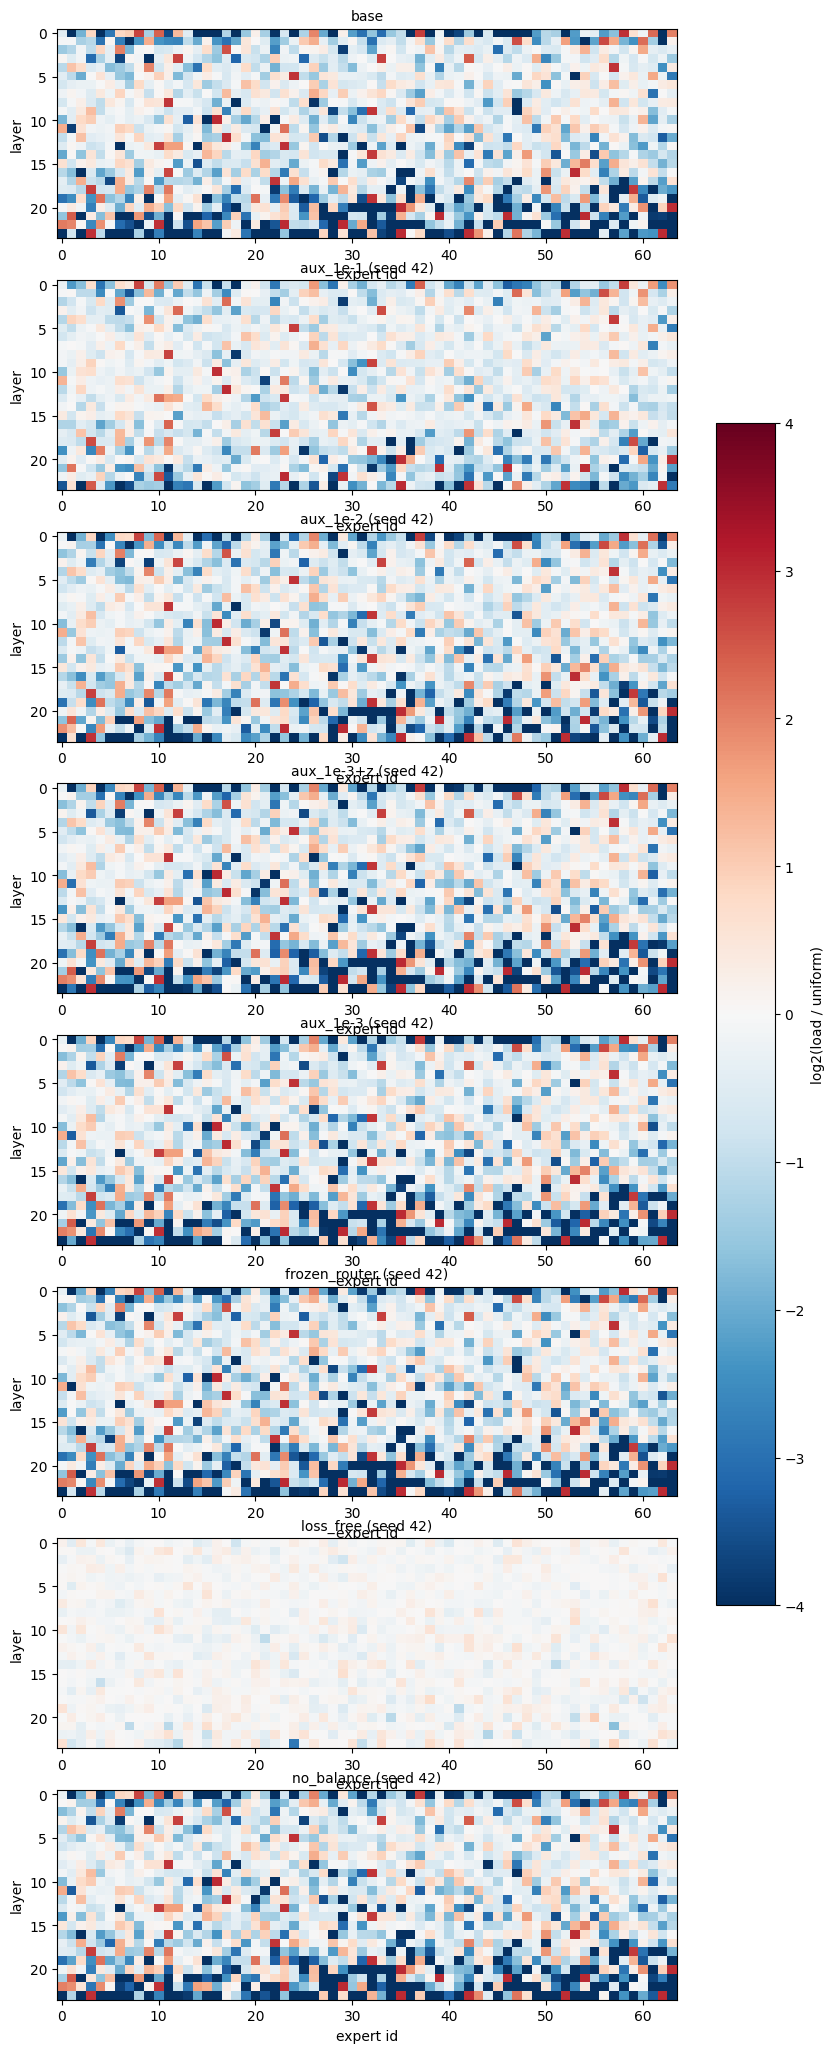

In [17]:
seed0_runs = [r for r in runs if r["seed"] == CFG2["seeds"][0]]
n_plots = 1 + len(seed0_runs)
fig, axes = plt.subplots(n_plots, 1, figsize=(10, 3.2 * n_plots))
im = plot_load_heatmap(base_counts, "base", axes[0])
for ax, r in zip(axes[1:], seed0_runs):
    plot_load_heatmap(torch.tensor(r["test_counts"]), f"{r['name']} (seed {r['seed']})", ax)
fig.colorbar(im, ax=axes, label="log2(load / uniform)", shrink=0.6)
plt.savefig(f"{WORK}/part2_heatmaps_all.png", dpi=120, bbox_inches="tight")
plt.show()

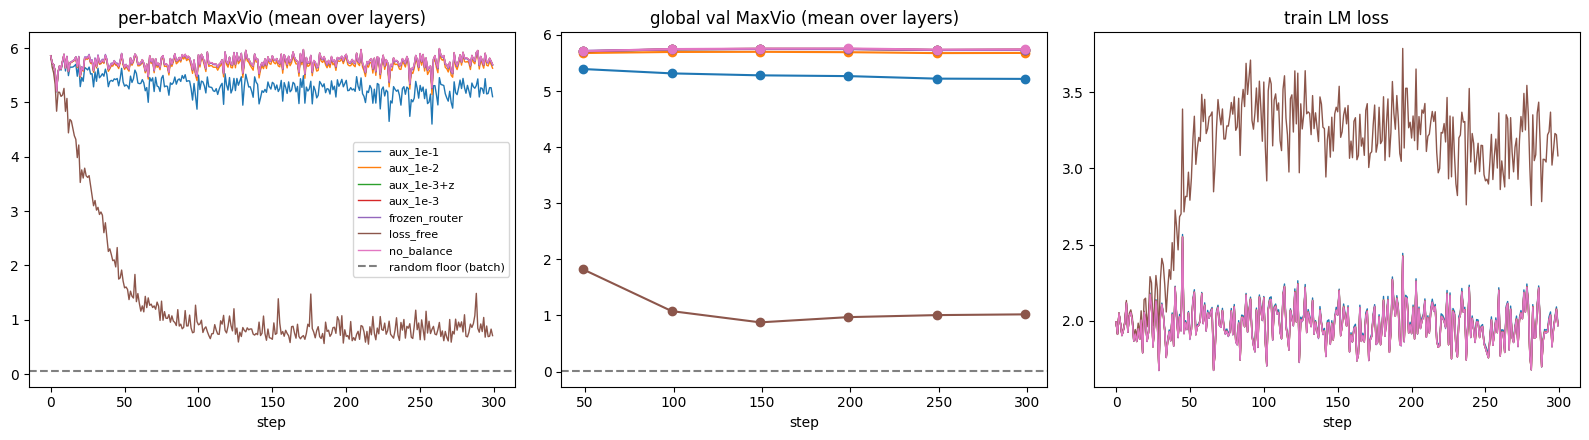

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for r in seed0_runs:
    h = r["history"]
    axes[0].plot(h["step"], h["batch_maxvio_mean"], label=r["name"], lw=1)
    axes[1].plot([v["step"] for v in h["val"]], [v["maxvio_mean"] for v in h["val"]], marker="o", label=r["name"])
    axes[2].plot(h["step"], h["lm_loss"], label=r["name"], lw=1)
axes[0].axhline(floor["batch"]["maxvio_mean"], color="grey", ls="--", label="random floor (batch)")
axes[1].axhline(floor["global_"]["maxvio_mean"], color="grey", ls="--", label="random floor (global)")
axes[0].set_title("per-batch MaxVio (mean over layers)")
axes[1].set_title("global val MaxVio (mean over layers)")
axes[2].set_title("train LM loss")
for ax in axes:
    ax.set_xlabel("step")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{WORK}/part2_curves.png", dpi=150)
plt.show()

In [19]:
# ===== put AFTER the results table cell (uses `runs`, `table`, `floor`) =====

# ---------- seed aggregation: mean ± std over seeds ----------
per_run = pd.DataFrame([dict(strategy=r["name"], seed=r["seed"], test_ppl=r["test"]["ppl"],
                             maxvio_mean=r["test"]["maxvio_mean"], entropy_mean=r["test"]["entropy_mean"],
                             jaccard=r["test"].get("jaccard_mean")) for r in runs])
agg = per_run.groupby("strategy").agg(["mean", "std", "count"])
display(agg.style.format("{:.4f}", na_rep="-"))
agg.to_csv(f"{WORK}/part2_results_seed_agg.csv")
print(f"noise floor (random router, global): MaxVio={floor['global_']['maxvio_mean']:.4f} "
      f"± {floor['global_']['maxvio_std']:.4f}")

# ---------- prediction-error table (pre-registered predictions vs measured) ----------
with open(f"{RUN_DIR}/predictions.json") as f:
    pred = json.load(f)
print("predictions registered at:", pred["timestamp"])

seed0 = per_run[per_run.seed == CFG2["seeds"][0]].set_index("strategy")
ref_ppl = seed0.loc["no_balance", "test_ppl"]
rows = []
for name, p in pred["predictions"].items():
    if name not in seed0.index:
        continue
    m = seed0.loc[name]
    measured = dict(ppl_delta_pct=(m.test_ppl - ref_ppl) / ref_ppl * 100,
                    maxvio=m.maxvio_mean, jaccard=m.jaccard)
    for metric, val in measured.items():
        if p.get(metric) is None:
            continue
        rows.append(dict(strategy=name, metric=metric, predicted=p[metric], measured=val,
                         error=val - p[metric]))
pred_err = pd.DataFrame(rows)
display(pred_err.style.format({"predicted": "{:.4f}", "measured": "{:.4f}", "error": "{:+.4f}"}))
pred_err.to_csv(f"{WORK}/part2_prediction_errors.csv", index=False)

noise floor (random router, global): MaxVio=0.0179 ± 0.0029
predictions registered at: 2026-10-03 19:35:51


,strategy,metric,predicted,measured,error
0,no_balance,ppl_delta_pct,0.0000,0.0000,+0.0000
1,no_balance,maxvio,5.7000,5.7155,+0.0155
2,no_balance,jaccard,0.9000,0.9012,+0.0012
3,aux_1e-3,ppl_delta_pct,0.0000,-0.0075,-0.0075
4,aux_1e-3,maxvio,5.7000,5.7090,+0.0090
5,aux_1e-3,jaccard,0.9000,0.9017,+0.0017
6,aux_1e-2,ppl_delta_pct,0.3000,0.0840,-0.2160
7,aux_1e-2,maxvio,5.3000,5.6472,+0.3472
8,aux_1e-2,jaccard,0.8700,0.8844,+0.0144
9,aux_1e-1,ppl_delta_pct,1.5000,1.6049,+0.1049
